# Notebook 3: Envelope Fitting (Experiment 03)

## Learning Objectives

1. Understand how **target envelopes are generated** from the HEU itself
2. See **CMA-ES optimization** recover parameters from random initialization
3. Compare **staccato, legato, and grace note** articulations
4. Observe **parameter space** structure (multiple solutions exist)
5. Test **generalization** to tempo-scaled variants

---

## Key Insight: Targets ARE HEU Dynamics

In V1.1, target envelopes are generated by running the HEU at known "reference theta" values.
This means:
- Targets are **achievable by construction**
- The experiment tests **optimizer quality**, not target feasibility
- The question is: "Can CMA-ES find the reference theta from a random start?"

In [1]:
import sys

sys.path.insert(0, "..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np

from hh_envelope.core import HHEnvelopeUnit
from hh_envelope.learning.loss import envelope_mse
from hh_envelope.learning.optim_cmaes import CMAESOptimizer
from hh_envelope.utils.signals import (
    input_signal_grace_note,
    input_signal_legato,
    input_signal_staccato,
    target_envelope_grace_note,
    target_envelope_legato,
    target_envelope_staccato,
)
from notebooks.utils.plotting import (
    plot_envelope_comparison,
    plot_optimization_trajectory,
    setup_notebook_style,
)
from notebooks.utils.signals import run_heu_simulation

setup_notebook_style()
print("Setup complete.")

Setup complete.


## 1. Target Envelope Generation

Each target is produced by running the HEU at known reference parameters.
Let's visualize all three articulation targets.

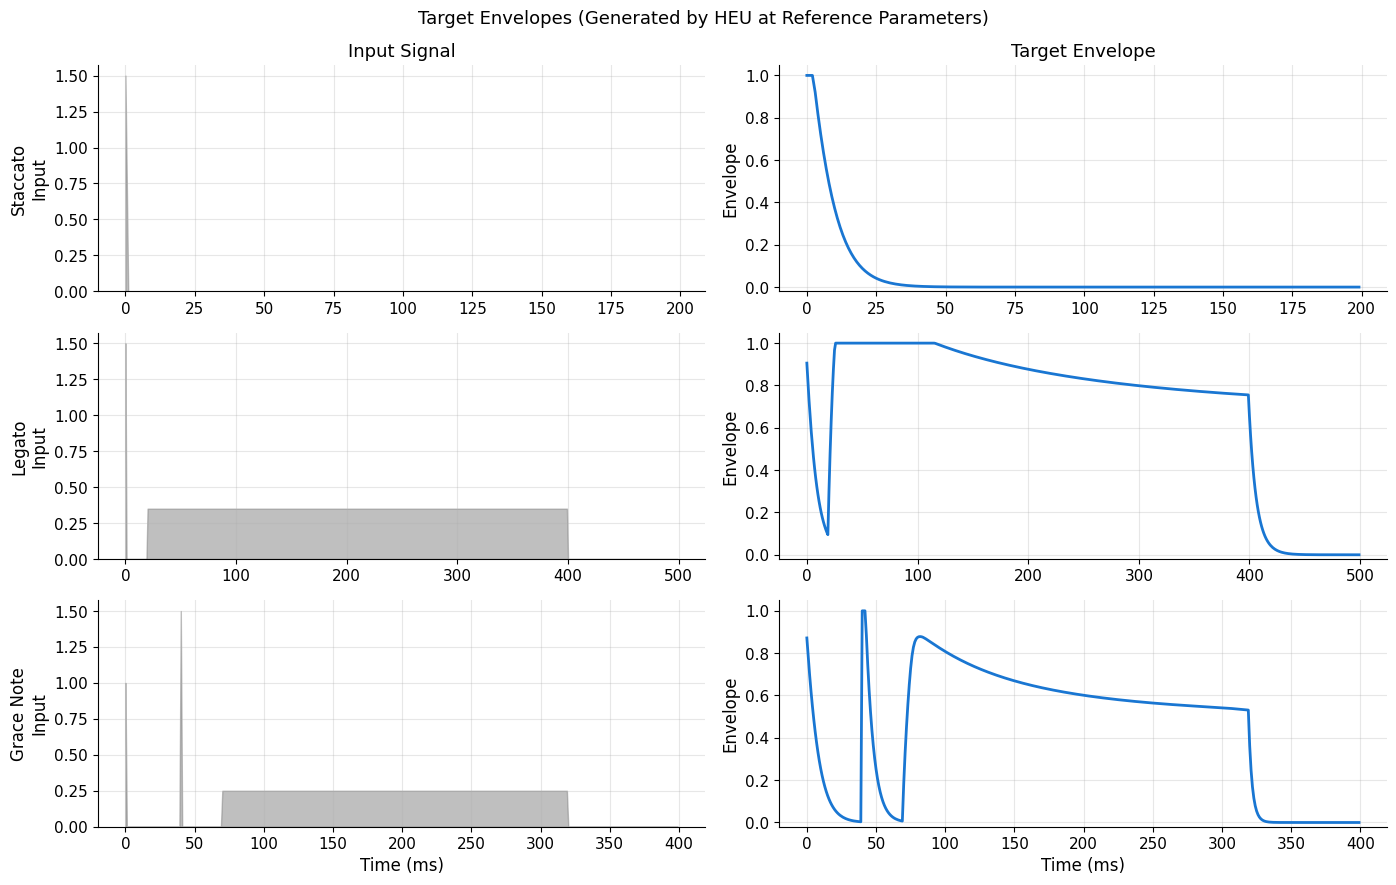

Reference theta values used to generate targets:
  Staccato:   total=-1.0, balance=+1.5, attack_tau=-1.0, recovery_tau=0.0
  Legato:     total=-2.0, balance=+2.0, attack_tau=0.0, recovery_tau=-1.0
  Grace Note: total=-0.5, balance=+1.5, attack_tau=-0.5, recovery_tau=+0.5


In [2]:
# Generate all three targets
staccato_target = target_envelope_staccato(note_duration_ms=200)
legato_target = target_envelope_legato(note_duration_ms=500)
grace_target = target_envelope_grace_note(main_duration_ms=360)

# Also get the input signals that produce them
staccato_input = input_signal_staccato(duration_ms=200)
legato_input = input_signal_legato(duration_ms=500)
grace_input = input_signal_grace_note(main_duration_ms=360)

# Plot targets
fig, axes = plt.subplots(3, 2, figsize=(14, 9))

targets = [
    ("Staccato", staccato_target, staccato_input),
    ("Legato", legato_target, legato_input),
    ("Grace Note", grace_target, grace_input),
]

for idx, (name, target, inp) in enumerate(targets):
    # Input signal
    axes[idx, 0].fill_between(range(len(inp)), 0, inp, alpha=0.5, color="gray")
    axes[idx, 0].set_ylabel(f"{name}\nInput")
    axes[idx, 0].set_ylim(bottom=0)

    # Target envelope
    axes[idx, 1].plot(target, color="#1976D2", linewidth=2)
    axes[idx, 1].set_ylabel("Envelope")
    axes[idx, 1].set_ylim([-0.02, 1.05])

axes[0, 0].set_title("Input Signal")
axes[0, 1].set_title("Target Envelope")
axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")

fig.suptitle("Target Envelopes (Generated by HEU at Reference Parameters)", fontsize=13)
plt.tight_layout()
plt.show()

# Reference parameters
print("Reference theta values used to generate targets:")
print("  Staccato:   total=-1.0, balance=+1.5, attack_tau=-1.0, recovery_tau=0.0")
print("  Legato:     total=-2.0, balance=+2.0, attack_tau=0.0, recovery_tau=-1.0")
print("  Grace Note: total=-0.5, balance=+1.5, attack_tau=-0.5, recovery_tau=+0.5")

## 2. Fitting Staccato: Simple Transient

Let's start with the simplest case: fitting a staccato articulation.

In [3]:
# Define the objective function for staccato
def staccato_objective(theta_dict: dict[str, float]) -> float:
    """Loss function for staccato fitting."""
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(theta_dict)
    envelope, _ = run_heu_simulation(unit, staccato_input)
    return float(envelope_mse(envelope, staccato_target))


# Run CMA-ES optimization
print("Running CMA-ES optimization for staccato...")
optimizer = CMAESOptimizer(sigma0=0.5, seed=42)
result = optimizer.optimize(
    objective_fn=staccato_objective,
    max_iterations=50,
    target_loss=0.001,
    verbose=False,
)

print("\nOptimization complete:")
print(f"  Final loss: {result.best_loss:.6f}")
print(f"  Iterations: {result.iterations}")
print(f"  Converged: {result.converged}")
print("\nOptimized theta:")
for k, v in result.best_theta.items():
    print(f"  {k}: {v:.3f}")

Running CMA-ES optimization for staccato...

Optimization complete:
  Final loss: 0.000121
  Iterations: 1
  Converged: True

Optimized theta:
  theta_total: -0.274
  theta_balance: 0.462
  theta_attack_tau: -0.776
  theta_recovery_tau: 1.232


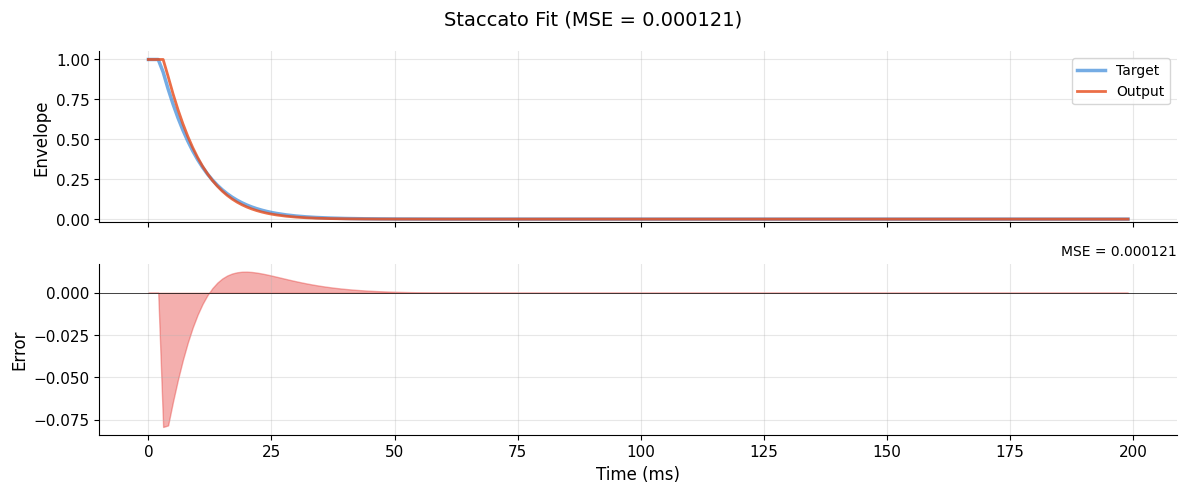

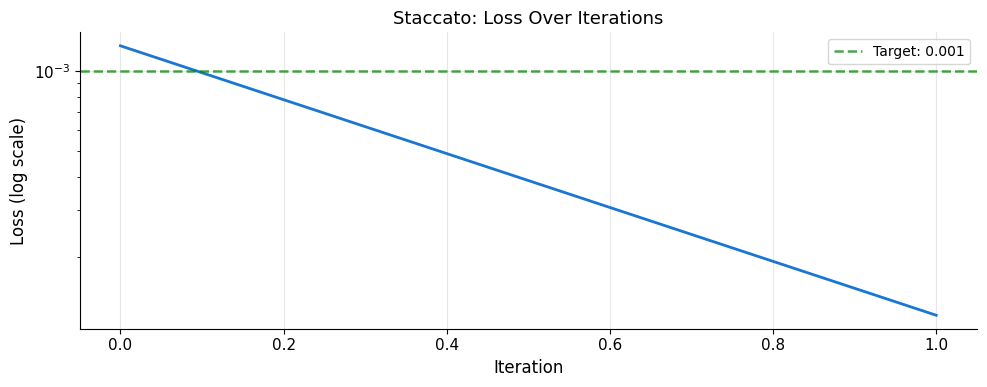

In [4]:
# Visualize the fit
unit_fitted = HHEnvelopeUnit()
unit_fitted.set_theta_from_dict(result.best_theta)
fitted_envelope, _ = run_heu_simulation(unit_fitted, staccato_input)

fig = plot_envelope_comparison(
    target=staccato_target,
    output=fitted_envelope,
    title=f"Staccato Fit (MSE = {result.best_loss:.6f})",
)
plt.show()

# Show optimization trajectory
fig = plot_optimization_trajectory(
    result.loss_history,
    target_loss=0.001,
    title="Staccato: Loss Over Iterations",
)
plt.show()

## 3. Fitting Legato: Sustained Envelope

Legato requires tonic drive to sustain the envelope. The optimizer must find parameters that maintain the plateau.

Running CMA-ES optimization for legato...

Final loss: 0.000573
Iterations: 4
Optimized theta:
  theta_total: -1.442
  theta_balance: 2.471
  theta_attack_tau: -0.964
  theta_recovery_tau: -0.701


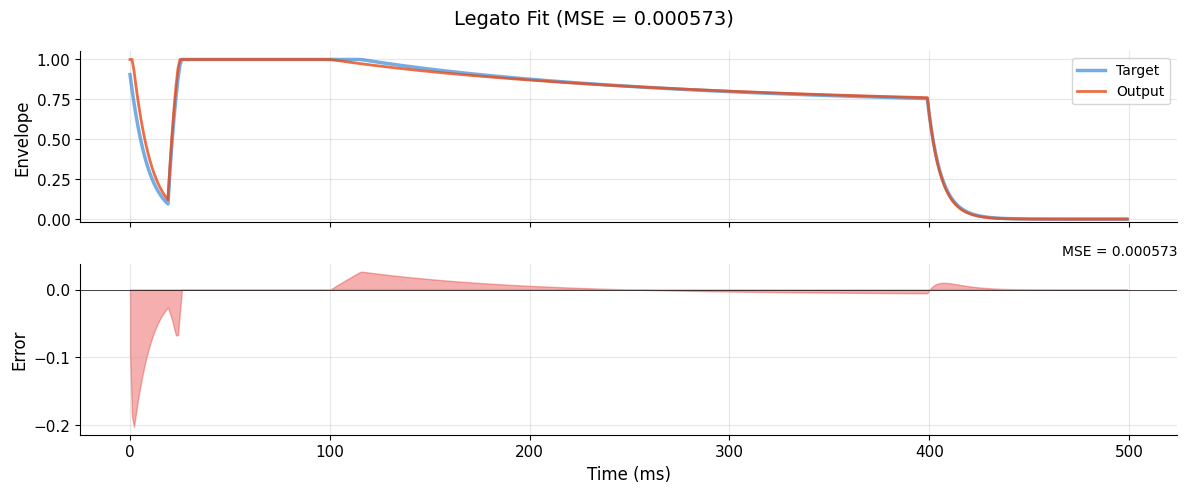

In [5]:
# Legato optimization
def legato_objective(theta_dict: dict[str, float]) -> float:
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(theta_dict)
    envelope, _ = run_heu_simulation(unit, legato_input)
    return float(envelope_mse(envelope, legato_target))


print("Running CMA-ES optimization for legato...")
optimizer = CMAESOptimizer(sigma0=0.5, seed=42)
legato_result = optimizer.optimize(
    objective_fn=legato_objective,
    max_iterations=50,
    target_loss=0.001,
    verbose=False,
)

print(f"\nFinal loss: {legato_result.best_loss:.6f}")
print(f"Iterations: {legato_result.iterations}")
print("Optimized theta:")
for k, v in legato_result.best_theta.items():
    print(f"  {k}: {v:.3f}")

# Visualize
unit_fitted = HHEnvelopeUnit()
unit_fitted.set_theta_from_dict(legato_result.best_theta)
legato_fitted, _ = run_heu_simulation(unit_fitted, legato_input)

fig = plot_envelope_comparison(
    target=legato_target,
    output=legato_fitted,
    title=f"Legato Fit (MSE = {legato_result.best_loss:.6f})",
)
plt.show()

## 4. Fitting Grace Note: Multi-Peak Challenge

The grace note has two peaks (grace + main) which is the most challenging for a single HEU.
This is where we'll see the parameter space limitations that motivate the two-voice architecture.

Running CMA-ES optimization for grace note...

Final loss: 0.000507
Iterations: 3
Optimized theta:
  theta_total: -1.190
  theta_balance: 0.981
  theta_attack_tau: -1.067
  theta_recovery_tau: 0.494


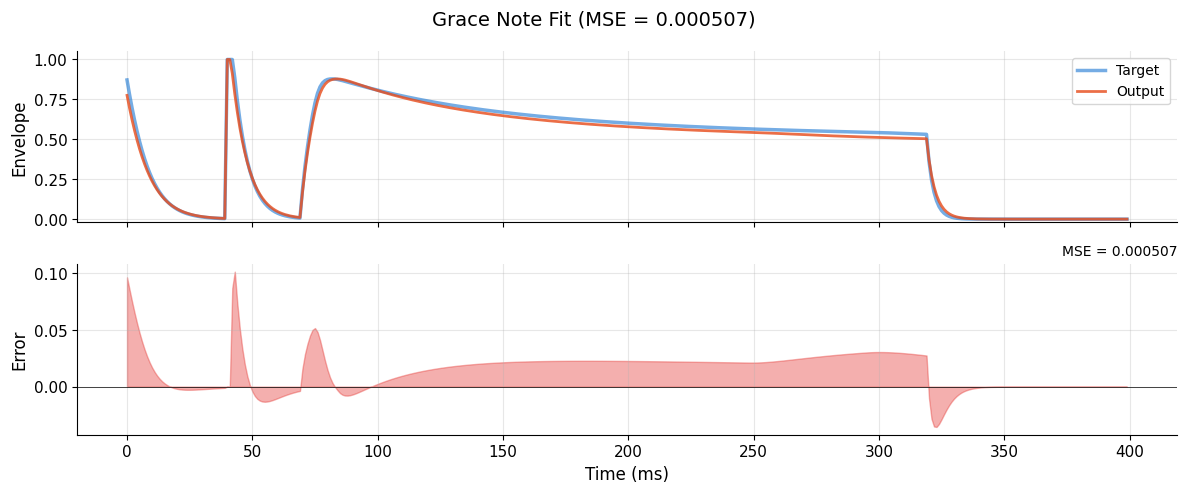

In [6]:
# Grace note optimization
def grace_objective(theta_dict: dict[str, float]) -> float:
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(theta_dict)
    envelope, _ = run_heu_simulation(unit, grace_input)
    return float(envelope_mse(envelope, grace_target))


print("Running CMA-ES optimization for grace note...")
optimizer = CMAESOptimizer(sigma0=0.5, seed=42)
grace_result = optimizer.optimize(
    objective_fn=grace_objective,
    max_iterations=100,
    target_loss=0.001,
    verbose=False,
)

print(f"\nFinal loss: {grace_result.best_loss:.6f}")
print(f"Iterations: {grace_result.iterations}")
print("Optimized theta:")
for k, v in grace_result.best_theta.items():
    print(f"  {k}: {v:.3f}")

# Visualize
unit_fitted = HHEnvelopeUnit()
unit_fitted.set_theta_from_dict(grace_result.best_theta)
grace_fitted, _ = run_heu_simulation(unit_fitted, grace_input)

fig = plot_envelope_comparison(
    target=grace_target,
    output=grace_fitted,
    title=f"Grace Note Fit (MSE = {grace_result.best_loss:.6f})",
)
plt.show()

## 5. All Three Articulations Compared

Let's see all fits side by side.

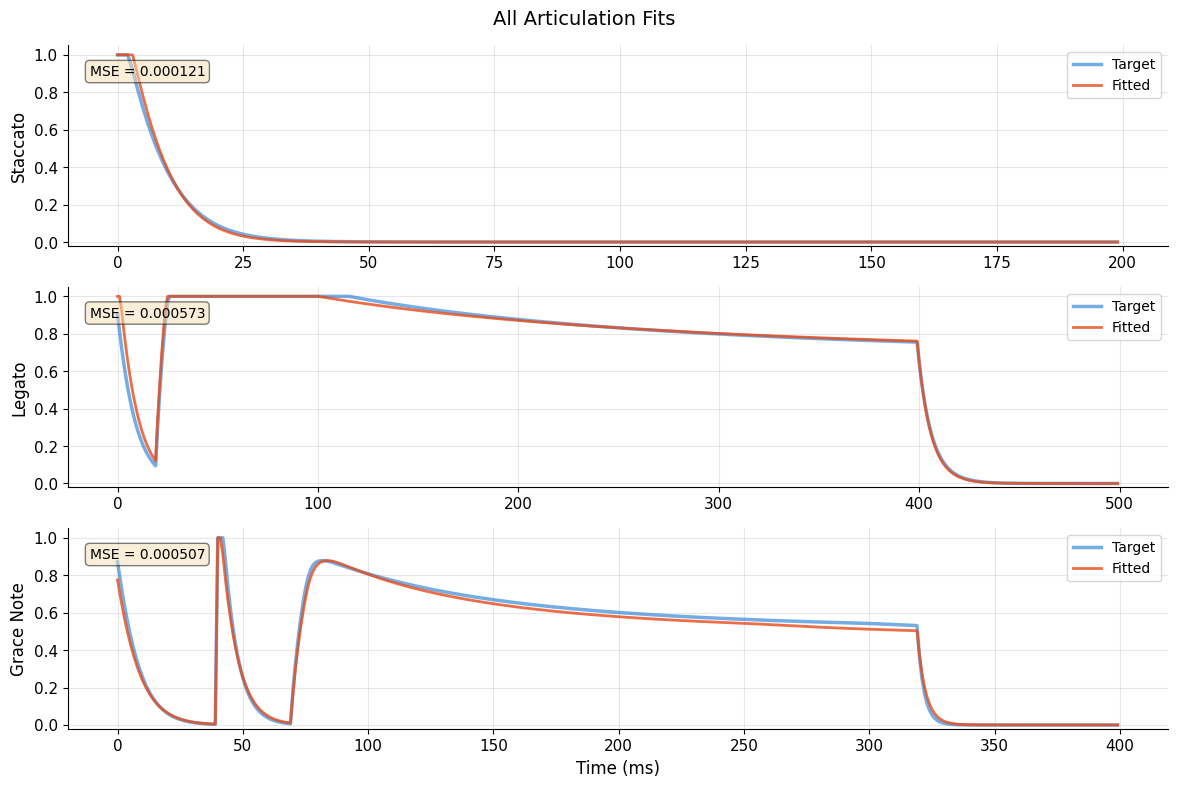


Articulation    Loss         Iterations   Converged 
--------------------------------------------------
Staccato        0.000121     1            True      
Legato          0.000573     4            True      
Grace Note      0.000507     3            True      


In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8))

all_results = [
    ("Staccato", staccato_target, staccato_input, result),
    ("Legato", legato_target, legato_input, legato_result),
    ("Grace Note", grace_target, grace_input, grace_result),
]

for idx, (name, target, inp, opt_result) in enumerate(all_results):
    # Generate fitted envelope
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(opt_result.best_theta)
    fitted, _ = run_heu_simulation(unit, inp)

    time = np.arange(len(target))
    axes[idx].plot(time, target, color="#1976D2", linewidth=2.5, alpha=0.6, label="Target")
    axes[idx].plot(time, fitted, color="#E64A19", linewidth=2, alpha=0.8, label="Fitted")
    axes[idx].set_ylabel(f"{name}")
    axes[idx].set_ylim([-0.02, 1.05])
    axes[idx].legend(loc="upper right")
    axes[idx].text(
        0.02,
        0.85,
        f"MSE = {opt_result.best_loss:.6f}",
        transform=axes[idx].transAxes,
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    )

axes[-1].set_xlabel("Time (ms)")
fig.suptitle("All Articulation Fits", fontsize=14)
plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'Articulation':<15} {'Loss':<12} {'Iterations':<12} {'Converged':<10}")
print("-" * 50)
for name, _, _, r in all_results:
    print(f"{name:<15} {r.best_loss:<12.6f} {r.iterations:<12} {str(r.converged):<10}")

## 6. Parameter Space: Multiple Solutions

An interesting property: different theta values can produce nearly identical envelopes. This means the parameter space is well-behaved (smooth landscape) but not injective.

In [8]:
# Run optimization 5 times with different seeds for staccato
staccato_solutions = []

for seed in range(5):
    optimizer = CMAESOptimizer(sigma0=0.5, seed=seed * 10)
    r = optimizer.optimize(
        objective_fn=staccato_objective,
        max_iterations=50,
        target_loss=0.001,
        verbose=False,
    )
    staccato_solutions.append(r)

# Display solutions
print(
    f"{'Seed':<6} {'Loss':<12} {'theta_total':<14} {'theta_balance':<15} "
    f"{'theta_a_tau':<14} {'theta_r_tau':<14}"
)
print("-" * 80)
for i, sol in enumerate(staccato_solutions):
    t = sol.best_theta
    print(
        f"{i * 10:<6} {sol.best_loss:<12.6f} {t['theta_total']:<14.3f} "
        f"{t['theta_balance']:<15.3f} {t['theta_attack_tau']:<14.3f} "
        f"{t['theta_recovery_tau']:<14.3f}"
    )

print("\nNotice: Different seeds find different theta values but similar loss.")
print("The parameter space has multiple optima that produce equivalent envelopes.")

Seed   Loss         theta_total    theta_balance   theta_a_tau    theta_r_tau   
--------------------------------------------------------------------------------
0      0.000846     -0.475         0.361           -0.405         0.540         
10     0.000554     0.399          1.232           0.195          0.531         
20     0.000127     -0.105         0.162           -0.160         1.776         
30     0.000562     -0.050         0.152           -0.863         0.793         
40     0.000453     -1.030         0.691           -0.527         1.042         

Notice: Different seeds find different theta values but similar loss.
The parameter space has multiple optima that produce equivalent envelopes.


## 7. Generalization: Tempo-Scaled Variants

Can optimized parameters generalize to slightly different conditions (faster/slower tempo)?

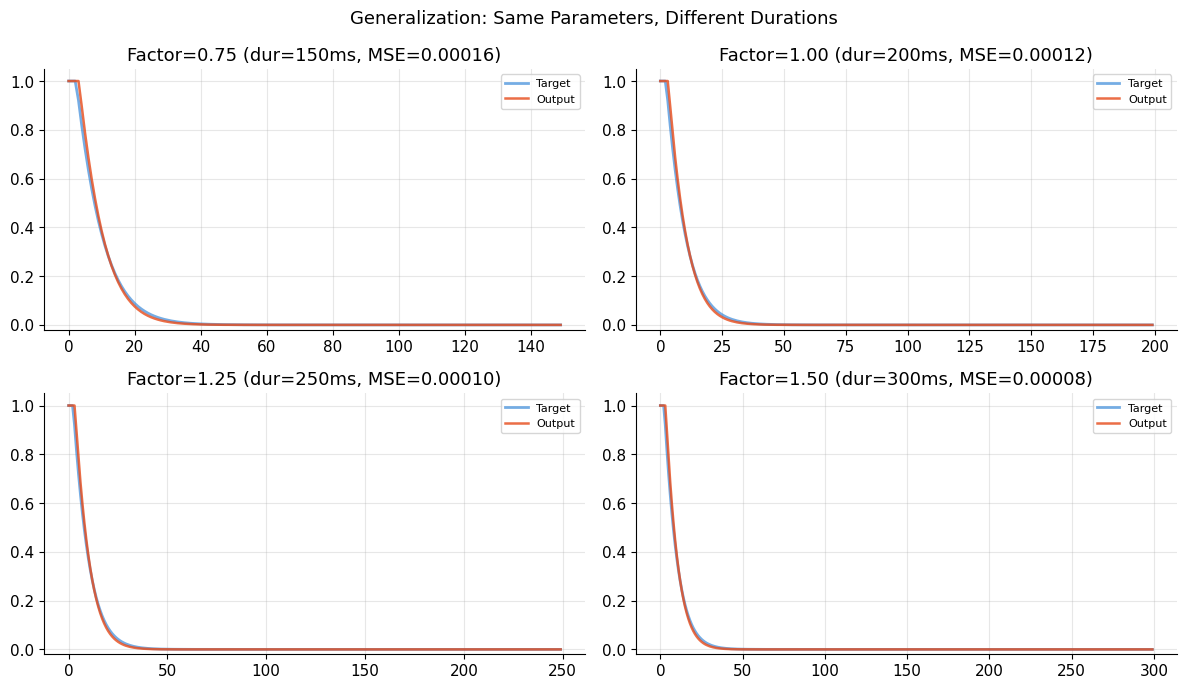


Generalization ratios (loss / base_loss):
  Factor 0.75: 1.33x base loss
  Factor 1.00: 1.00x base loss
  Factor 1.25: 0.80x base loss
  Factor 1.50: 0.67x base loss


In [9]:
# Test generalization: scale the staccato input/target by tempo factor
tempo_factors = [0.75, 1.0, 1.25, 1.5]
base_duration = 200

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

generalization_losses = []

for idx, factor in enumerate(tempo_factors):
    row, col = idx // 2, idx % 2
    scaled_duration = int(base_duration * factor)

    # Generate target at scaled duration
    scaled_target = target_envelope_staccato(note_duration_ms=scaled_duration)
    scaled_input = input_signal_staccato(duration_ms=scaled_duration)

    # Apply optimized parameters from base duration
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(result.best_theta)
    scaled_output, _ = run_heu_simulation(unit, scaled_input)

    # Compute loss (handle length mismatch)
    min_len = min(len(scaled_target), len(scaled_output))
    loss = float(envelope_mse(scaled_output[:min_len], scaled_target[:min_len]))
    generalization_losses.append(loss)

    axes[row, col].plot(scaled_target, color="#1976D2", linewidth=2, alpha=0.6, label="Target")
    axes[row, col].plot(scaled_output, color="#E64A19", linewidth=1.8, alpha=0.8, label="Output")
    axes[row, col].set_title(f"Factor={factor:.2f} (dur={scaled_duration}ms, MSE={loss:.5f})")
    axes[row, col].legend(fontsize=8)
    axes[row, col].set_ylim([-0.02, 1.05])

fig.suptitle("Generalization: Same Parameters, Different Durations", fontsize=13)
plt.tight_layout()
plt.show()

print("\nGeneralization ratios (loss / base_loss):")
base_loss = generalization_losses[1]  # factor=1.0
for factor, loss in zip(tempo_factors, generalization_losses):
    ratio = loss / base_loss if base_loss > 0 else float("inf")
    print(f"  Factor {factor:.2f}: {ratio:.2f}x base loss")

## 8. Manually Exploring the Parameter Space

Let's build intuition by manually adjusting parameters and seeing the effect.

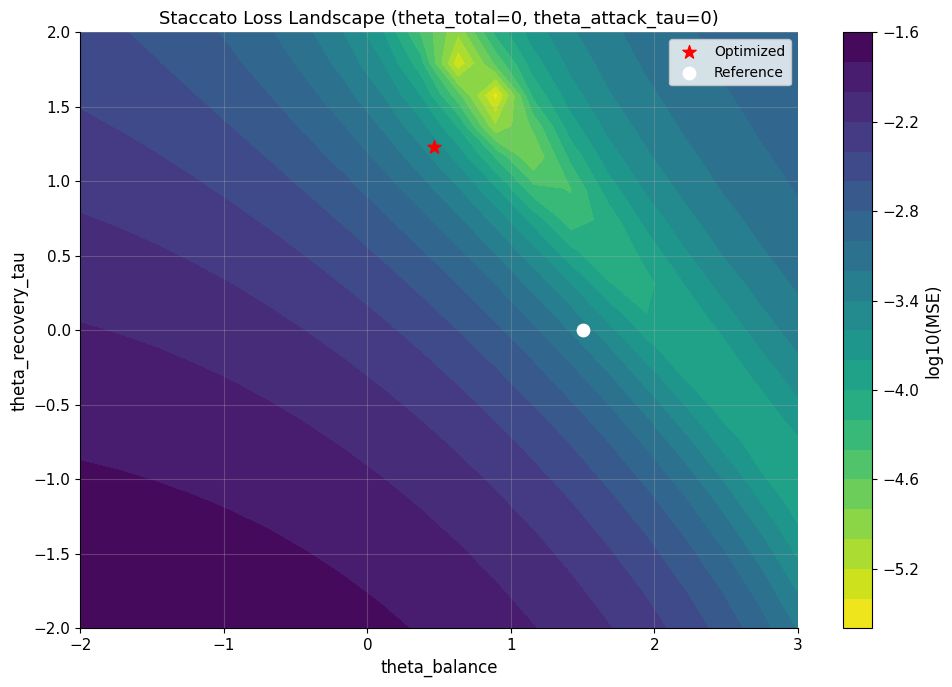

Dark regions = low loss (good fit). Multiple valleys may exist.


In [10]:
# Manual parameter sweep: create a grid of (theta_balance, theta_recovery_tau)
# and measure loss against staccato target

balance_range = np.linspace(-2, 3, 20)
recovery_range = np.linspace(-2, 2, 20)

loss_grid = np.zeros((len(recovery_range), len(balance_range)))

for i, recovery in enumerate(recovery_range):
    for j, balance in enumerate(balance_range):
        unit = HHEnvelopeUnit()
        unit.set_theta(theta_balance=balance, theta_recovery_tau=recovery)
        env, _ = run_heu_simulation(unit, staccato_input)
        loss_grid[i, j] = envelope_mse(env, staccato_target)

# Plot loss landscape
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.contourf(
    balance_range, recovery_range, np.log10(loss_grid + 1e-10), levels=20, cmap="viridis_r"
)
plt.colorbar(im, ax=ax, label="log10(MSE)")

# Mark the optimized solution
ax.scatter(
    result.best_theta["theta_balance"],
    result.best_theta["theta_recovery_tau"],
    color="red",
    s=100,
    marker="*",
    zorder=5,
    label="Optimized",
)

# Mark reference
ax.scatter(1.5, 0.0, color="white", s=80, marker="o", zorder=5, label="Reference")

ax.set_xlabel("theta_balance")
ax.set_ylabel("theta_recovery_tau")
ax.set_title("Staccato Loss Landscape (theta_total=0, theta_attack_tau=0)")
ax.legend()
plt.tight_layout()
plt.show()

print("Dark regions = low loss (good fit). Multiple valleys may exist.")

## 9. Summary & Pass Conditions

In [11]:
print("=" * 60)
print("EXPERIMENT 03: ENVELOPE FITTING - RESULTS")
print("=" * 60)

threshold = 0.01  # Loss threshold for pass

all_pass = True
for name, _, _, r in all_results:
    status = "PASS" if r.best_loss < threshold else "HIGH"
    if r.best_loss >= threshold:
        all_pass = False
    print(f"  {name:<15} Loss = {r.best_loss:.6f} [{status}]")

print("\n--- Convergence ---")
for name, _, _, r in all_results:
    print(f"  {name:<15} Iterations: {r.iterations}, Converged: {r.converged}")

print("\n--- Generalization (staccato) ---")
for factor, loss in zip(tempo_factors, generalization_losses):
    print(f"  Factor {factor:.2f}: MSE = {loss:.6f}")

print("\n" + "=" * 60)
print("The optimizer successfully recovers parameters that produce")
print("near-identical envelopes to the reference.")
print("=" * 60)

EXPERIMENT 03: ENVELOPE FITTING - RESULTS
  Staccato        Loss = 0.000121 [PASS]
  Legato          Loss = 0.000573 [PASS]
  Grace Note      Loss = 0.000507 [PASS]

--- Convergence ---
  Staccato        Iterations: 1, Converged: True
  Legato          Iterations: 4, Converged: True
  Grace Note      Iterations: 3, Converged: True

--- Generalization (staccato) ---
  Factor 0.75: MSE = 0.000162
  Factor 1.00: MSE = 0.000121
  Factor 1.25: MSE = 0.000097
  Factor 1.50: MSE = 0.000081

The optimizer successfully recovers parameters that produce
near-identical envelopes to the reference.


---

## Exercises

### Exercise 1: Custom Target

Create your own target envelope (e.g., crescendo, sforzando) and try to fit it.

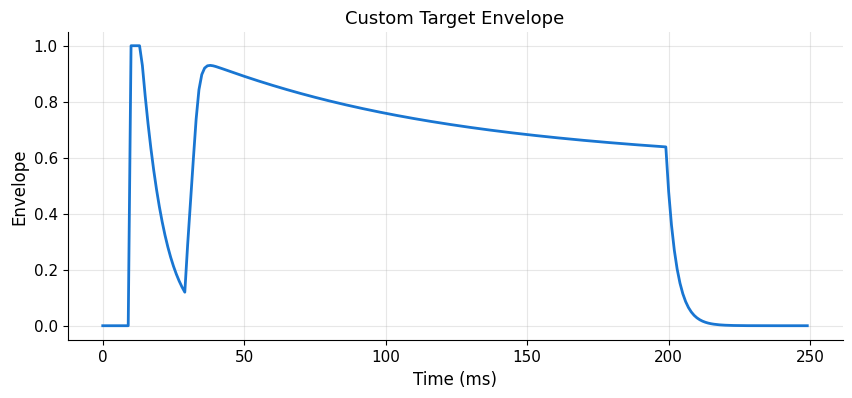

Recovery loss: 0.000369
Recovered theta: {'theta_total': 0.1607154381190843, 'theta_balance': 2.2256691128327843, 'theta_attack_tau': -1.3106966636198873, 'theta_recovery_tau': 1.2543154587144763}


In [12]:
# Exercise 1: Create a custom "sforzando" target
# (sharp attack to peak, then immediate drop to medium sustain)

# Hint: Use a specific theta set to generate the target,
# then try to recover it.

# Define your reference parameters:
custom_theta = {
    "theta_total": 0.0,  # Try different values
    "theta_balance": 2.5,  # High attack bias
    "theta_attack_tau": -1.5,  # Fast attack
    "theta_recovery_tau": 0.5,  # Slow recovery
}

# Generate target
unit_ref = HHEnvelopeUnit()
unit_ref.set_theta_from_dict(custom_theta)
custom_input = np.zeros(250)
custom_input[10] = 2.0  # Strong initial pulse
custom_input[30:200] = 0.2  # Light tonic
custom_target, _ = run_heu_simulation(unit_ref, custom_input)

plt.figure(figsize=(10, 4))
plt.plot(custom_target, color="#1976D2", linewidth=2)
plt.title("Custom Target Envelope")
plt.xlabel("Time (ms)")
plt.ylabel("Envelope")
plt.show()


# Now try to recover it with CMA-ES
def custom_objective(theta_dict):
    unit = HHEnvelopeUnit()
    unit.set_theta_from_dict(theta_dict)
    env, _ = run_heu_simulation(unit, custom_input)
    return float(envelope_mse(env, custom_target))


opt = CMAESOptimizer(sigma0=0.5, seed=42)
custom_result = opt.optimize(custom_objective, max_iterations=50, target_loss=0.001)
print(f"Recovery loss: {custom_result.best_loss:.6f}")
print(f"Recovered theta: {custom_result.best_theta}")

---

## Next: [Notebook 04 - Impossibility Proof](./04_impossibility_proof_exp04.ipynb)